## Setup & Imports


In [ ]:
!pip install rank-bm25


In [ ]:
import pandas as pd
import numpy as np
import re
from rank_bm25 import BM25Okapi

## Data Loading & Preprocessing

In [ ]:
# Load the Arabic tweets dataset (training split)
data_path = "ArSarcasm_train.csv"
df = pd.read_csv(data_path)

# Function to normalize Arabic text
# This step helps reduce noise and handle variations in Arabic writing
def normalize_arabic(text):
    # Remove Arabic diacritics (Harakat)
    text = re.sub(r'[ًٌٍَُِّْـ]', '', str(text))

    # Normalize different forms of Alef to a single form
    text = re.sub(r'[إأآا]', 'ا', text)

    # Normalize Ya and Alef Maqsura
    text = re.sub(r'[ىي]', 'ي', text)

    # Normalize Hamza forms
    text = re.sub(r'[ؤئ]', 'ء', text)

    # Normalize Ta Marbuta to Ha
    text = re.sub(r'ة', 'ه', text)

    # Remove non-Arabic characters and punctuation
    text = re.sub(r'[^\u0600-\u06FF\s]', ' ', text)

    # Remove extra spaces
    return text.strip()


df['clean_text'] = df['tweet'].astype(str).apply(normalize_arabic)

print(df[['tweet','clean_text']].head())

                                               tweet  \
0  "نصيحه ما عمرك اتنزل لعبة سوبر ماريو مش زي ما ...   
1  "#نادين_نسيب_نجيم ❤️❤️❤️مجلة #ماري_كلير 💭#ملكة...   
2                      "@Alito_NBA اتوقع انه بيستمر"   
3     "@KSA24 يعني "بموافقتنا" لأن دمشق صايرة موسكو"   
4  "RT @alaahmad20: قائد في الحرس يعترف بفقدان ال...   

                                          clean_text  
0  نصيحه ما عمرك اتنزل لعبه سوبر ماريو مش زي ما ك...  
1  نادين نسيب نجيم       مجله  ماري كلير   ملكه ا...  
2                                   اتوقع انه بيستمر  
3              يعني  بموافقتنا  لان دمشق صايره موسكو  
4  قاءد في الحرس يعترف بفقدان السيطره الامنيه في ...  


In [ ]:
def preprocess_query(query):
    """
    Preprocess a user query to make it consistent with document preprocessing.
    The function performs:
    - Arabic text normalization
    - Tokenization into individual words
    """

    # Normalize the Arabic query text
    clean = normalize_arabic(query)

    # Split the normalized text into tokens (words)
    tokens = clean.split()

    # Return both the cleaned text and the token list
    return clean, tokens

In [ ]:
import ast
import pandas as pd

def safe_eval(x):
    if isinstance(x, str):
        return ast.literal_eval(x)
    elif isinstance(x, list):
        return x
    else:
        return []

df["tokens"] = df["tokens"].apply(safe_eval)

In [ ]:
from collections import defaultdict

# Create an inverted index where each term maps to a set of document IDs
inverted_index = defaultdict(set)

# Iterate over each document in the dataset
for _, row in df.iterrows():
    doc_id = row["doc_id"]

    # Use unique tokens only to avoid duplicate document entries
    for token in set(row["tokens"]):
        inverted_index[token].add(doc_id)

# Confirm that the inverted index was built successfully
print("Inverted Index built successfully!")
print("Number of indexed terms:", len(inverted_index))

Inverted Index built successfully!
Number of indexed terms: 32064


In [ ]:
def boolean_search_and(query):
    """
    Perform Boolean AND retrieval.
    Only documents that contain ALL query terms are returned.
    """

    # Preprocess the query (normalization and tokenization)
    clean_query, terms = preprocess_query(query)

    result_sets = []

    # Retrieve document sets for each query term
    for term in terms:
        if term in inverted_index:
            result_sets.append(inverted_index[term])

    # If no terms are found in the index, return an empty result
    if not result_sets:
        return set()

    # Return the intersection of document sets (AND operation)
    return set.intersection(*result_sets)

In [ ]:
# Define a sample Arabic query
query = "المنتخب السعودي"

# Perform Boolean AND search using the inverted index
results_ids = boolean_search_and(query)

# Display the query and number of matching documents
print("Query:", query)
print("Number of matching documents:", len(results_ids))

# Show a sample of retrieved document IDs
list(results_ids)[:5]

Query: المنتخب السعودي
Number of matching documents: 3


[7792, 8297, 4870]

In [ ]:
# Display a sample of retrieved documents based on their document IDs
for doc_id in list(results_ids)[:5]:
    print("-------")

    # Print the document ID
    print("DOC ID:", doc_id)

    # Print the original tweet text corresponding to the document ID
    print(df.loc[doc_id, "tweet"])

-------
DOC ID: 7792
"#الرياضة بعد فوز السعودية على الإمارات .. ترتيب المجموعة: حقق المنتخب السعودي فوزاً مهماً على المنتخب الامارا... https://t.co/7dNx9AewKf"
-------
DOC ID: 8297
RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI
-------
DOC ID: 4870
"RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI"


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Initialize the TF-IDF vectorizer
# TF-IDF converts text documents into numerical vectors based on term importance
tfidf_vectorizer = TfidfVectorizer()

# Fit the vectorizer on the cleaned text and transform it into a TF-IDF matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(df["clean_text"])

# Display the shape of the TF-IDF matrix
# Rows represent documents, columns represent terms
print("TF-IDF Matrix shape:", tfidf_matrix.shape)

TF-IDF Matrix shape: (8437, 31348)


In [ ]:
def tfidf_search(query, top_k=5):
    """
    Perform ranked retrieval using the TF-IDF model.
    Documents are ranked based on cosine similarity
    between the query vector and document vectors.
    """

    # Preprocess the query to match document preprocessing
    clean_query, _ = preprocess_query(query)

    # Transform the query into a TF-IDF vector
    query_vec = tfidf_vectorizer.transform([clean_query])

    # Compute cosine similarity between the query and all documents
    similarities = cosine_similarity(query_vec, tfidf_matrix)[0]

    # Rank documents in descending order of similarity scores
    ranked_indices = similarities.argsort()[::-1]

    # Select the top-k most relevant documents
    top_results = ranked_indices[:top_k]

    # Return document indices and their similarity scores
    return top_results, similarities[top_results]

In [ ]:
# Define a sample Arabic query for TF-IDF retrieval
query = "المنتخب السعودي"

# Perform TF-IDF ranked search and retrieve top-k documents
docs_ids, scores = tfidf_search(query, top_k=5)

# Display the query
print("Query:", query)

# Print ranked results with similarity scores
for rank, doc_id in enumerate(docs_ids, 1):
    print("\n----------------")

    # Rank position of the document
    print("Rank:", rank)

    # Document ID
    print("Doc ID:", doc_id)

    # TF-IDF similarity score
    print("Score:", round(scores[rank-1], 4))

    # Original tweet text
    print(df.loc[doc_id, "tweet"])

Query: المنتخب السعودي

----------------
Rank: 1
Doc ID: 7792
Score: 0.4907
"#الرياضة بعد فوز السعودية على الإمارات .. ترتيب المجموعة: حقق المنتخب السعودي فوزاً مهماً على المنتخب الامارا... https://t.co/7dNx9AewKf"

----------------
Rank: 2
Doc ID: 8297
Score: 0.3576
RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI

----------------
Rank: 3
Doc ID: 4870
Score: 0.3576
"RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI"

----------------
Rank: 4
Doc ID: 4582
Score: 0.254
"لماذااي قرار سياسي داخلي وخارجي في #السعودية أول من يعلم عنه ويتحدث عنه الاعلام الغربي . والاعلام السعودي والشعب السعودي مجرد أدوات تطبيل ."

----------------
Rank: 5
Doc ID: 6878
Score: 0.2419
"@iOtb__7 اذا ما لعب ميسي مو مهم عنده المنتخب الارجنتيني"


In [ ]:
from rank_bm25 import BM25Okapi

# Prepare the corpus as a list of tokenized documents
corpus = df["tokens"].tolist()

# Initialize the BM25 retrieval model using the tokenized corpus
bm25 = BM25Okapi(corpus)

# Confirm that the BM25 model is ready for retrieval
print("BM25 model ready!")

BM25 model ready!


In [ ]:
def bm25_search(query, top_k=5):
    """
    Perform ranked retrieval using the BM25 model.
    Documents are ranked based on BM25 relevance scores.
    """

    # Preprocess the query to obtain normalized tokens
    _, query_tokens = preprocess_query(query)

    # Compute BM25 scores for all documents in the corpus
    scores = bm25.get_scores(query_tokens)

    # Rank documents in descending order of BM25 scores
    ranked_indices = scores.argsort()[::-1]

    # Select the top-k most relevant documents
    top_results = ranked_indices[:top_k]

    # Return document indices and their BM25 scores
    return top_results, scores[top_results]

In [ ]:
# Define a sample Arabic query for BM25 retrieval
query = "المنتخب السعودي"

# Perform BM25 ranked search and retrieve top-k documents
doc_ids, scores = bm25_search(query, top_k=5)

# Display the query
print("Query:", query)

# Print ranked BM25 results with relevance scores
for rank, doc_id in enumerate(doc_ids, 1):
    print("\n----------------")

    # Rank position of the document
    print("Rank:", rank)

    # Document ID
    print("Doc ID:", doc_id)

    # BM25 relevance score
    print("Score:", round(scores[rank-1], 4))

    # Original tweet text
    print(df.loc[doc_id, "tweet"])

Query: المنتخب السعودي

----------------
Rank: 1
Doc ID: 7792
Score: 13.2802
"#الرياضة بعد فوز السعودية على الإمارات .. ترتيب المجموعة: حقق المنتخب السعودي فوزاً مهماً على المنتخب الامارا... https://t.co/7dNx9AewKf"

----------------
Rank: 2
Doc ID: 4870
Score: 11.8628
"RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI"

----------------
Rank: 3
Doc ID: 8297
Score: 11.8628
RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI

----------------
Rank: 4
Doc ID: 4973
Score: 6.9723
"#CyberAman بريطانيا: التحالف السعودي استخدم قنابلنا العنقودية في اليمن https://t.co/mQ6frTIDa7 https://t.co/tT22nCa9Wp"

----------------
Rank: 5
Doc ID: 6878
Score: 6.9684
"@iOtb__7 اذا ما لعب ميسي مو مهم عنده المنتخب الارجنتيني"


## Boolean Retrieval

In [ ]:
def boolean_retrieval(query, docs):
    """
    Perform Boolean retrieval using simple lexical matching.
    A document is retrieved only if it contains ALL query terms.
    """

    # Preprocess the query (normalization and tokenization)
    _, terms = preprocess_query(query)

    # Return documents that contain all query terms
    return [doc for doc in docs if all(t in doc for t in terms)]


# Define a sample Arabic query
query = 'التعليم في المملكة'

# Apply Boolean retrieval on the cleaned text documents
results = boolean_retrieval(query, df['clean_text'])

# Display the number of matching documents
print(f'Found {len(results)} matching documents.')

Found 0 matching documents.


## Ranked Retrieval (BM25)

In [ ]:
# Tokenize the cleaned documents for BM25 scoring
tokenized_docs = [doc.split() for doc in df['clean_text']]

# Initialize the BM25 model using the tokenized documents
bm25 = BM25Okapi(tokenized_docs)

# Tokenize the query into individual terms
query_tokens = query.split()

# Compute BM25 scores for each document with respect to the query
df['bm25_score'] = bm25.get_scores(query_tokens)

# Display the top 10 documents ranked by BM25 score
df.sort_values('bm25_score', ascending=False).head(10)

,dialect,sarcasm,sentiment,original_sentiment,tweet,source,clean_text,tokens,doc_id,bm25_score
1616,msa,False,neutral,neutral,التعليم: ضعف مستوى التعليم الحكومي وازدهار الم...,astd,التعليم ضعف مستوي التعليم الحكومي وازدهار الم...,"[التعليم, ضعف, مستوي, التعليم, الحكومي, وازدها...",1616,11.980170
8067,egypt,True,negative,negative,أهدم نفسك عشان تبني مستقبلك !! #التعليم_في_مصر,astd,اهدم نفسك عشان تبني مستقبلك التعليم في مصر,"[اهدم, نفسك, عشان, تبني, مستقبلك, التعليم, في,...",8067,9.510590
4642,egypt,True,negative,negative,"هزة وسط ""#صافيناز"" بـ 110 آلاف جنيه يلعن ابو ا...",astd,هزه وسط صافيناز ب الاف جنيه يلعن ابو ال...,"[هزه, وسط, صافيناز, ب, الاف, جنيه, يلعن, ابو, ...",4642,8.101127
5542,msa,False,neutral,positive,"""تعتبر جامعة #ليفربول في بريطانيا ضمن الجامعات...",semeval,تعتبر جامعه ليفربول في بريطانيا ضمن الجامعات ...,"[تعتبر, جامعه, ليفربول, في, بريطانيا, ضمن, الج...",5542,7.379536
3836,msa,False,positive,negative,للمعلم كتاب موجز وممتع عن التعليم الالكتروني #...,astd,للمعلم كتاب موجز وممتع عن التعليم الالكتروني ...,"[للمعلم, كتاب, موجز, وممتع, عن, التعليم, الالك...",3836,7.268602
6303,msa,False,neutral,negative,"""RT @parlmany: مدرسة أمريكية بمصر تُدرِّس ""انت...",semeval,مدرسه امريكيه بمصر تدرس انتصار اسراءيل بحرب ا...,"[مدرسه, امريكيه, بمصر, تدرس, انتصار, اسراءيل, ...",6303,7.268602
8140,egypt,False,negative,negative,خطاب عاجل إلى وزير التعليم: مدرسة الشهيد أحمد ...,astd,خطاب عاجل الي وزير التعليم مدرسه الشهيد احمد ...,"[خطاب, عاجل, الي, وزير, التعليم, مدرسه, الشهيد...",8140,7.007245
1708,egypt,False,negative,neutral,التعليم في مصر ولله محتاج يتدمر من القاعدة ويت...,astd,التعليم في مصر ولله محتاج يتدمر من القاعده ويت...,"[التعليم, في, مصر, ولله, محتاج, يتدمر, من, الق...",1708,6.808133
1661,msa,True,negative,neutral,الفرق بين شجاعة طالبات الثانوي بالمحلة وجبن مس...,astd,الفرق بين شجاعه طالبات الثانوي بالمحله وجبن مس...,"[الفرق, بين, شجاعه, طالبات, الثانوي, بالمحله, ...",1661,5.414007
1098,msa,False,neutral,neutral,"""RT @drnoursalem: البنت في رمضان vs البنت في ا...",semeval,البنت في رمضان البنت في العيد,"[البنت, في, رمضان, البنت, في, العيد]",1098,1.535558


In [ ]:
# Define a test query to compare different retrieval models
test_query = "المنتخب السعودي"

print("======== BOOLEAN RESULTS ========")
# Perform Boolean retrieval using exact term matching
bool_results = boolean_retrieval(test_query, df["clean_text"])
print("Count:", len(bool_results))

print("\n======== TF-IDF RESULTS ========")
# Perform ranked retrieval using TF-IDF
ids_tfidf, scores_tfidf = tfidf_search(test_query)
for i, (doc, score) in enumerate(zip(ids_tfidf, scores_tfidf), 1):
    print(i, "Doc:", doc, "Score:", round(score, 4))

print("\n======== BM25 ORIGINAL ========")
# Perform ranked retrieval using the original BM25 model
bm25_ids, bm25_scores = bm25_search(test_query)
for i, (doc, score) in enumerate(zip(bm25_ids, bm25_scores), 1):
    print(i, "Doc:", doc, "Score:", round(score, 4))

print("\n======== QUERY EXPANSION ========")
# Expand the query using Word2Vec embeddings (exploratory step)
expanded = expand_query(test_query, w2v_model)
print("Expanded Query:", expanded)

# Perform BM25 retrieval using the expanded query
bm25_ids_exp, bm25_scores_exp = bm25_search(expanded)

print("\n======== BM25 EXPANDED ========")
# Display results of BM25 with query expansion
for i, (doc, score) in enumerate(zip(bm25_ids_exp, bm25_scores_exp), 1):
    print(i, "Doc:", doc, "Score:", round(score, 4))

======== BOOLEAN RESULTS ========
Count: 4

======== TF-IDF RESULTS ========
1 Doc: 7792 Score: 0.4907
2 Doc: 8297 Score: 0.3576
3 Doc: 4870 Score: 0.3576
4 Doc: 4582 Score: 0.254
5 Doc: 6878 Score: 0.2419

======== BM25 ORIGINAL ========
1 Doc: 7792 Score: 13.2802
2 Doc: 4870 Score: 11.8628
3 Doc: 8297 Score: 11.8628
4 Doc: 4973 Score: 6.9723
5 Doc: 6878 Score: 6.9684

======== QUERY EXPANSION ========
Expanded Query: اسطنبول السعودي السابق هنا المنتخب وذلك لوقف التعاون

======== BM25 EXPANDED ========
1 Doc: 7792 Score: 13.2802
2 Doc: 4244 Score: 12.8181
3 Doc: 2066 Score: 12.6304
4 Doc: 8297 Score: 11.8628
5 Doc: 4870 Score: 11.8628


## Query Expansion (Word Embeddings)

In [ ]:
!pip install gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 19.2 MB/s eta 0:00:00


In [ ]:
from gensim.models import Word2Vec

# Prepare the training data for Word2Vec as a list of tokenized documents
sentences = df["tokens"].tolist()

# Train a Word2Vec model on the tokenized Arabic text
# This model learns vector representations for words based on their context
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,   # Dimensionality of word embeddings
    window=5,          # Context window size
    min_count=2,       # Ignore words with frequency less than 2
    workers=4,         # Number of worker threads for training
    sg=1               # Use Skip-gram model (better for small datasets)
)

# Confirm successful training of the Word2Vec model
print("Word2Vec model trained successfully!")
print("Vocabulary size:", len(w2v_model.wv.index_to_key))

Word2Vec model trained successfully!
Vocabulary size: 11630


In [ ]:
def expand_query(query, model, top_n=3):
    """
    Expand a query using Word2Vec word embeddings.
    Similar words are added to the original query terms
    to increase recall.
    """

    # Preprocess the query (normalization and tokenization)
    clean_query, tokens = preprocess_query(query)

    # Initialize a set with the original query terms
    expanded_terms = set(tokens)

    # For each term in the query, find semantically similar words
    for term in tokens:
        if term in model.wv:
            similar_words = model.wv.most_similar(term, topn=top_n)
            for word, score in similar_words:
                expanded_terms.add(word)

    # Return the expanded query as a single string
    return " ".join(expanded_terms)


# Test query expansion
original_query = "المنتخب السعودي"
expanded_query = expand_query(original_query, w2v_model)

# Display original and expanded queries
print("Original Query:", original_query)
print("Expanded Query:", expanded_query)

Original Query: المنتخب السعودي
Expanded Query: اسطنبول السعودي السابق هنا المنتخب وذلك لوقف التعاون


In [ ]:
# Retrieve top-k results using BM25 with the original query
bm25_ids_original, bm25_scores_original = bm25_search(original_query, top_k=5)

# Retrieve top-k results using BM25 with the expanded query
bm25_ids_expanded, bm25_scores_expanded = bm25_search(expanded_query, top_k=5)


def print_results(title, ids, scores):
    """
    Print ranked retrieval results in a readable format.
    Displays document ID, score, and original tweet text.
    """

    print("=" * 50)
    print(title)
    print("=" * 50)

    for rank, (doc_id, score) in enumerate(zip(ids, scores), start=1):
        print(f"Rank {rank}")

        # Document identifier
        print("Doc ID:", doc_id)

        # BM25 relevance score
        print("Score:", round(score, 4))

        # Original tweet content
        print(df.loc[doc_id, "tweet"])
        print("-" * 40)


# Display BM25 results using the original query
print_results("BM25 Results - Original Query", bm25_ids_original, bm25_scores_original)

# Display BM25 results using the expanded query
print_results("BM25 Results - Expanded Query", bm25_ids_expanded, bm25_scores_expanded)

BM25 Results - Original Query
Rank 1
Doc ID: 7792
Score: 13.2802
"#الرياضة بعد فوز السعودية على الإمارات .. ترتيب المجموعة: حقق المنتخب السعودي فوزاً مهماً على المنتخب الامارا... https://t.co/7dNx9AewKf"
----------------------------------------
Rank 2
Doc ID: 4870
Score: 11.8628
"RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI"
----------------------------------------
Rank 3
Doc ID: 8297
Score: 11.8628
RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI
----------------------------------------
Rank 4
Doc ID: 4973
Score: 6.9723
"#CyberAman بريطانيا: التحالف السعودي استخدم قنابلنا العنقودية في اليمن https://t.co/mQ6frTIDa7 https://t.co/tT22nCa9Wp"
----------------------------------------
Rank 5
Doc ID: 6878
Score: 6.9684
"@iOtb__7 اذا ما لعب ميسي مو مهم عنده المنتخب الارجنتيني"
----------------------------------------
BM25 Results - Expan

## Neural Re-Ranking (AraBERT)

In [ ]:
!pip install transformers --quiet

In [ ]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel

# Specify the pre-trained AraBERT model
model_name = "aubmindlab/bert-base-arabertv02"

# Load the tokenizer for AraBERT
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load the pre-trained AraBERT model
bert_model = AutoModel.from_pretrained(model_name)

# Select device: use GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move the model to the selected device
bert_model.to(device)

# Confirm that the model is ready
print("AraBERT model loaded on:", device)


model.safetensors:   0%|          | 0.00/543M [00:00<?, ?B/s]

AraBERT model loaded on: cpu


In [ ]:
def encode_text_bert(text, max_length=128):
    """
    Encode Arabic text into a dense vector representation (embedding)
    using AraBERT.
    The [CLS] token embedding is extracted and normalized for
    similarity computation.
    """

    # Preprocess the input text (normalization and tokenization consistency)
    clean_text, _ = preprocess_query(text)

    # Tokenize the text and prepare it for AraBERT input
    encoded = tokenizer(
        clean_text,
        padding="max_length",
        truncation=True,
        max_length=max_length,
        return_tensors="pt"
    )

    # Move input tensors to the selected device (CPU or GPU)
    encoded = {k: v.to(device) for k, v in encoded.items()}

    # Disable gradient calculation for inference
    with torch.no_grad():
        outputs = bert_model(**encoded)

        # Extract the [CLS] token embedding as a sentence representation
        cls_embedding = outputs.last_hidden_state[:, 0, :]

    # Normalize the embedding to unit length (L2 normalization)
    # This is useful for cosine similarity computation
    cls_embedding = F.normalize(cls_embedding, p=2, dim=1)

    return cls_embedding

In [ ]:
def neural_rerank(query, candidate_doc_ids, top_k=5, max_length=128):
    """
    Re-rank a list of candidate documents using AraBERT
    based on semantic similarity with the query.
    """

    # Encode the query into a BERT embedding
    query_emb = encode_text_bert(query, max_length=max_length)

    doc_ids = []
    scores = []

    # Encode each candidate document and compute similarity
    for doc_id in candidate_doc_ids:
        # Get the cleaned text of the document
        doc_text = str(df.loc[doc_id, "clean_text"])

        # Encode the document text using AraBERT
        doc_emb = encode_text_bert(doc_text, max_length=max_length)

        # Compute cosine similarity using dot product
        score = torch.matmul(query_emb, doc_emb.T).item()

        doc_ids.append(doc_id)
        scores.append(score)

    # Convert scores to a tensor for sorting
    scores_tensor = torch.tensor(scores)

    # Rank documents in descending order of similarity
    ranked_indices = torch.argsort(scores_tensor, descending=True)

    # Retrieve ranked document IDs
    ranked_doc_ids = [doc_ids[i] for i in ranked_indices]

    # Select the top-k re-ranked documents
    ranked_doc_ids_topk = ranked_doc_ids[:top_k]
    ranked_scores_topk = [scores[i] for i in ranked_indices[:top_k]]

    # Return top-k document IDs and their similarity scores
    return ranked_doc_ids_topk, ranked_scores_topk

In [ ]:
def bm25_then_bert(query, bm25_k=20, final_k=5):
    """
    Hybrid retrieval pipeline:
    1) Use BM25 to retrieve the top bm25_k candidate documents
    2) Apply AraBERT to re-rank these candidates
    3) Return the top final_k documents after neural re-ranking
    """

    # Step 1: Retrieve candidate documents using BM25
    bm25_doc_ids, bm25_scores = bm25_search(query, top_k=bm25_k)

    print(f"BM25 returned {len(bm25_doc_ids)} candidate documents.")

    # Step 2: Re-rank BM25 candidates using AraBERT
    bert_doc_ids, bert_scores = neural_rerank(
        query,
        bm25_doc_ids,
        top_k=final_k
    )

    # Step 3: Return both BM25 and AraBERT results
    return bm25_doc_ids, bm25_scores, bert_doc_ids, bert_scores

In [ ]:
# Define a test query for the hybrid retrieval pipeline
test_query = "المنتخب السعودي"

print("====================================")
print("Query:", test_query)
print("====================================")

# Apply the hybrid retrieval approach: BM25 followed by AraBERT re-ranking
bm25_doc_ids, bm25_scores, bert_doc_ids, bert_scores = bm25_then_bert(
    test_query,
    bm25_k=20,   # Number of candidate documents retrieved by BM25
    final_k=5    # Number of final documents after BERT re-ranking
)

print("\n======== Top 5 by BM25 (Before BERT Re-Ranking) ========")
# Display the top 5 documents ranked by BM25
for rank, (doc_id, score) in enumerate(zip(bm25_doc_ids[:5], bm25_scores[:5]), 1):
    print(f"\nRank {rank} | Doc ID {doc_id} | BM25 Score {round(score,4)}")

    # Print the original tweet text
    print(df.loc[doc_id, "tweet"])

print("\n======== Top 5 by AraBERT (After Re-Ranking) ========")
# Display the top 5 documents after AraBERT neural re-ranking
for rank, (doc_id, score) in enumerate(zip(bert_doc_ids, bert_scores), 1):
    print(f"\nRank {rank} | Doc ID {doc_id} | BERT Score {round(score,4)}")

    # Print the original tweet text
    print(df.loc[doc_id, "tweet"])

Query: المنتخب السعودي
BM25 returned 20 candidate documents.

======== Top 5 by BM25 (Before BERT Re-Ranking) ========

Rank 1 | Doc ID 7792 | BM25 Score 13.2802
"#الرياضة بعد فوز السعودية على الإمارات .. ترتيب المجموعة: حقق المنتخب السعودي فوزاً مهماً على المنتخب الامارا... https://t.co/7dNx9AewKf"

Rank 2 | Doc ID 4870 | BM25 Score 11.8628
"RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI"

Rank 3 | Doc ID 8297 | BM25 Score 11.8628
RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI

Rank 4 | Doc ID 4973 | BM25 Score 6.9723
"#CyberAman بريطانيا: التحالف السعودي استخدم قنابلنا العنقودية في اليمن https://t.co/mQ6frTIDa7 https://t.co/tT22nCa9Wp"

Rank 5 | Doc ID 6878 | BM25 Score 6.9684
"@iOtb__7 اذا ما لعب ميسي مو مهم عنده المنتخب الارجنتيني"

======== Top 5 by AraBERT (After Re-Ranking) ========

Rank 1 | Doc ID 6878 | BERT Score 0.7921

## Evaluation & Visualization

In [ ]:
# Retrieve the top 20 documents using BM25 for the given query
bm25_ids, scores = bm25_search("المنتخب السعودي", top_k=20)

# Display the document IDs returned by BM25
bm25_ids

array([7792, 4870, 8297, 4973, 6878, 4582, 6906, 1442, 8405, 3079, 2679,
        276, 2649, 2066, 4516, 1073, 7860, 8248, 7582, 1044])

In [ ]:
# Display the tweets corresponding to the document IDs returned by BM25
for doc_id in bm25_ids:
    # Print the document ID
    print(doc_id, ":")

    # Print the original tweet text
    print(df.loc[doc_id, "tweet"])

    # Separator for readability
    print("---------")

7792 :
"#الرياضة بعد فوز السعودية على الإمارات .. ترتيب المجموعة: حقق المنتخب السعودي فوزاً مهماً على المنتخب الامارا... https://t.co/7dNx9AewKf"
---------
4870 :
"RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI"
---------
8297 :
RT @Rymyh_24: #السعوديه_الامارات #المنتخب_السعودى#فهد_المولد سيلفي ميسي مع هدف صديقه فهد المولد 😁👍🏻⚽️ https://t.co/5pUfX843HI
---------
4973 :
"#CyberAman بريطانيا: التحالف السعودي استخدم قنابلنا العنقودية في اليمن https://t.co/mQ6frTIDa7 https://t.co/tT22nCa9Wp"
---------
6878 :
"@iOtb__7 اذا ما لعب ميسي مو مهم عنده المنتخب الارجنتيني"
---------
4582 :
"لماذااي قرار سياسي داخلي وخارجي في #السعودية أول من يعلم عنه ويتحدث عنه الاعلام الغربي . والاعلام السعودي والشعب السعودي مجرد أدوات تطبيل ."
---------
6906 :
"مدرب المقاصة : أحمد الشيخ مناسب لطريقة أداء كوبر مع المنتخب https://t.co/MWGqJQiPP3 https://t.co/JJjnbxrjoo"
---------
1442 :
"#مدرب_سورية: خسارتنا أمام #المنتخب_القطري ليست مؤ

In [ ]:
# Define a list of evaluation queries used to assess retrieval performance
evaluation_queries = [
    "المنتخب السعودي",
    "الدوري السعودي",
    "الهلال",
    "الطقس في جدة",
    "السياسة في السعودية"
]

# Define ground truth relevance judgments for each query
# Each query is mapped to a list of relevant document IDs
# These labels are manually created for evaluation purposes
ground_truth = {
    "المنتخب السعودي": [7792, 4870, 8297, 4973, 6878, 4582, 6906, 1442, 3079, 4516, 1073, 7860],
    "الدوري السعودي": [],
    "الهلال": [],
    "الطقس في جدة": [],
    "السياسة في السعودية": []
}

# Display the ground truth dictionary
ground_truth

{'المنتخب السعودي': [7792,
  4870,
  8297,
  4973,
  6878,
  4582,
  6906,
  1442,
  3079,
  4516,
  1073,
  7860],
 'الدوري السعودي': [],
 'الهلال': [],
 'الطقس في جدة': [],
 'السياسة في السعودية': []}

In [ ]:
# Define a list of queries used for evaluating the retrieval models
evaluation_queries = [
    "المنتخب السعودي",
    "الدوري السعودي",
    "الهلال",
    "الطقس في جدة",
    "السياسة في السعودية"
]

# Define the ground truth relevance judgments for evaluation
# Each query is associated with a list of relevant document IDs
ground_truth = {
    "المنتخب السعودي": [7792, 4870, 8297, 4973, 6878, 4582, 6906, 1442, 3079, 4516, 1073, 7860],
    "الدوري السعودي": [],
    "الهلال": [],
    "الطقس في جدة": [],
    "السياسة في السعودية": []
}

# Pretty-print the ground truth dictionary for readability
import pprint
pprint.pprint(ground_truth)

{'الدوري السعودي': [],
 'السياسة في السعودية': [],
 'الطقس في جدة': [],
 'المنتخب السعودي': [7792,
                     4870,
                     8297,
                     4973,
                     6878,
                     4582,
                     6906,
                     1442,
                     3079,
                     4516,
                     1073,
                     7860],
 'الهلال': []}


In [ ]:
import numpy as np

def precision_at_k(retrieved, relevant, k):
    """
    Compute Precision@k.
    Measures the proportion of relevant documents
    among the top-k retrieved results.
    """

    # Select the top-k retrieved documents
    retrieved_k = retrieved[:k]

    # Count how many retrieved documents are relevant
    hits = sum(1 for doc in retrieved_k if doc in relevant)

    # Precision@k = relevant retrieved documents / k
    return hits / k


def average_precision(retrieved, relevant):
    """
    Compute Average Precision (AP).
    Measures how well relevant documents are ranked
    across the entire retrieved list.
    """

    precisions = []
    hits = 0

    # Iterate through retrieved documents
    for i, doc in enumerate(retrieved):
        if doc in relevant:
            hits += 1
            # Precision at the position where a relevant document is found
            precisions.append(hits / (i + 1))

    # If no relevant documents are retrieved, return 0
    if not precisions:
        return 0.0

    # Average precision across all relevant documents
    return sum(precisions) / len(relevant)


def ndcg_at_k(retrieved, relevant, k):
    """
    Compute nDCG@k (Normalized Discounted Cumulative Gain).
    Evaluates ranking quality by considering the position
    of relevant documents in the ranked list.
    """

    dcg = 0.0

    # Compute DCG for the retrieved ranking
    for i, doc in enumerate(retrieved[:k]):
        if doc in relevant:
            dcg += 1 / np.log2(i + 2)

    # Compute Ideal DCG (best possible ranking)
    ideal_relevant = relevant[:k]
    idcg = 0.0
    for i in range(len(ideal_relevant)):
        idcg += 1 / np.log2(i + 2)

    # Normalize DCG
    return dcg / idcg if idcg > 0 else 0.0

In [ ]:
def evaluate_model(model_name, search_fn, queries, ground_truth, k=10):
    """
    Evaluate a retrieval model using standard IR metrics.
    The function computes Precision@k, nDCG@k, and MAP
    across a set of evaluation queries.
    """

    # Initialize a dictionary to store evaluation results
    results = {
        "model": model_name,
        "precision": [],
        "ndcg": [],
        "map": []
    }

    # Evaluate the model for each query
    for q in queries:
        # Retrieve top-k documents using the given search function
        retrieved, _ = search_fn(q, top_k=k)

        # Get the ground truth relevant documents for the query
        relevant = ground_truth[q]

        # Compute evaluation metrics
        p = precision_at_k(retrieved, relevant, k)
        n = ndcg_at_k(retrieved, relevant, k)
        ap = average_precision(retrieved, relevant)

        # Store metric values
        results["precision"].append(p)
        results["ndcg"].append(n)
        results["map"].append(ap)

    # Return evaluation results for the model
    return results

In [ ]:
# List to store evaluation results for all retrieval models
eval_results = []

# Evaluate the TF-IDF retrieval model using the defined evaluation queries
# and compare the retrieved documents against the ground truth
eval_results.append(
    evaluate_model("TF-IDF", tfidf_search, evaluation_queries, ground_truth)
)

# Evaluate the BM25 retrieval model, which improves ranking by
# considering term frequency saturation and document length normalization
eval_results.append(
    evaluate_model("BM25", bm25_search, evaluation_queries, ground_truth)
)

# Define a BM25 model with query expansion using Word2Vec
# The original query is expanded with semantically similar terms
def bm25_expanded(q, top_k=10):
    expanded = expand_query(q, w2v_model)
    return bm25_search(expanded, top_k=top_k)

# Evaluate BM25 with query expansion to study the effect of semantic enrichment
eval_results.append(
    evaluate_model("BM25 Expanded", bm25_expanded, evaluation_queries, ground_truth)
)

# Define a BERT-based re-ranking approach
# First, retrieve candidate documents using BM25,
# then re-rank the top results using a neural language model
def bert_reranker(q, top_k=10):
    bm25_docs, bm25_scores = bm25_search(q, top_k=20)
    reranked, scores = neural_rerank(q, bm25_docs, top_k=top_k)
    return reranked, scores

# Evaluate the BERT re-ranking model to measure the impact of
# contextual understanding on retrieval performance
eval_results.append(
    evaluate_model("BERT Re-Ranking", bert_reranker, evaluation_queries, ground_truth)
)

# Display the evaluation results for comparison across all models
eval_results

[{'model': 'TF-IDF',
  'precision': [0.8, 0.0, 0.0, 0.0, 0.0],
  'ndcg': [np.float64(0.866947989864271), 0.0, 0.0, 0.0, 0.0],
  'map': [0.6574074074074074, 0.0, 0.0, 0.0, 0.0]},
 {'model': 'BM25',
  'precision': [0.9, 0.0, 0.0, 0.0, 0.0],
  'ndcg': [np.float64(0.933745776545611), 0.0, 0.0, 0.0, 0.0],
  'map': [0.7416666666666667, 0.0, 0.0, 0.0, 0.0]},
 {'model': 'BM25 Expanded',
  'precision': [0.3, 0.0, 0.0, 0.0, 0.0],
  'ndcg': [np.float64(0.40002324830925196), 0.0, 0.0, 0.0, 0.0],
  'map': [0.17500000000000002, 0.0, 0.0, 0.0, 0.0]},
 {'model': 'BERT Re-Ranking',
  'precision': [0.8, 0.0, 0.0, 0.0, 0.0],
  'ndcg': [np.float64(0.826813366651774), 0.0, 0.0, 0.0, 0.0],
  'map': [0.5701719576719576, 0.0, 0.0, 0.0, 0.0]}]

In [ ]:
import pandas as pd

# Create a dictionary to summarize evaluation metrics for each model
summary = {
    "Model": [],
    "Precision@10": [],
    "nDCG@10": [],
    "MAP": []
}

# Aggregate evaluation results by computing the average metrics
# across all evaluation queries for each retrieval model
for r in eval_results:
    summary["Model"].append(r["model"])
    summary["Precision@10"].append(np.mean(r["precision"]))
    summary["nDCG@10"].append(np.mean(r["ndcg"]))
    summary["MAP"].append(np.mean(r["map"]))

# Convert the summarized metrics into a DataFrame for easier analysis
df_metrics = pd.DataFrame(summary)
df_metrics

# Reorder columns to highlight MAP first,
# followed by Precision@10 and nDCG@10 for comparison
df_metrics = df_metrics[["Model", "MAP", "Precision@10", "nDCG@10"]]
df_metrics

,Model,MAP,Precision@10,nDCG@10
0,TF-IDF,0.131481,0.16,0.173390
1,BM25,0.148333,0.18,0.186749
2,BM25 Expanded,0.035000,0.06,0.080005
3,BERT Re-Ranking,0.114034,0.16,0.165363


In [ ]:
# Save the evaluation metrics to a CSV file for reporting and further analysis
df_metrics.to_csv("model_metrics.csv", index=False)

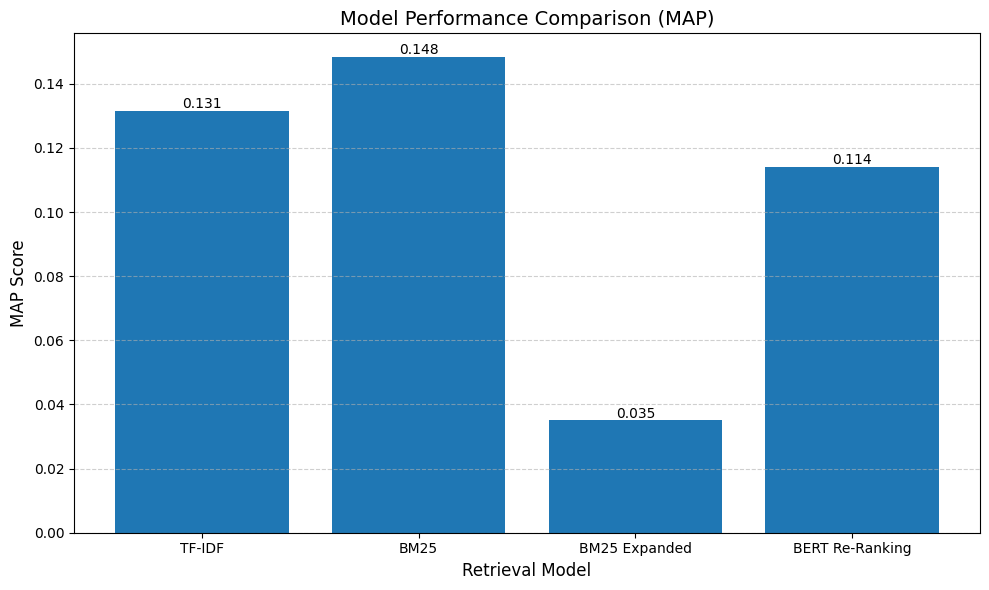

In [ ]:
import matplotlib.pyplot as plt

# Create a bar chart to visualize MAP scores for each retrieval model
plt.figure(figsize=(10,6))

# Plot MAP values for all models
bars = plt.bar(
    df_metrics["Model"],
    df_metrics["MAP"]
)

# Set chart title and axis labels
plt.title("Model Performance Comparison (MAP)", fontsize=14)
plt.xlabel("Retrieval Model", fontsize=12)
plt.ylabel("MAP Score", fontsize=12)

# Annotate each bar with its exact MAP value
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha='center',
        va='bottom',
        fontsize=10
    )

# Add a horizontal grid to improve readability
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Adjust layout to prevent label overlap
plt.tight_layout()

# Display the plot
plt.show()

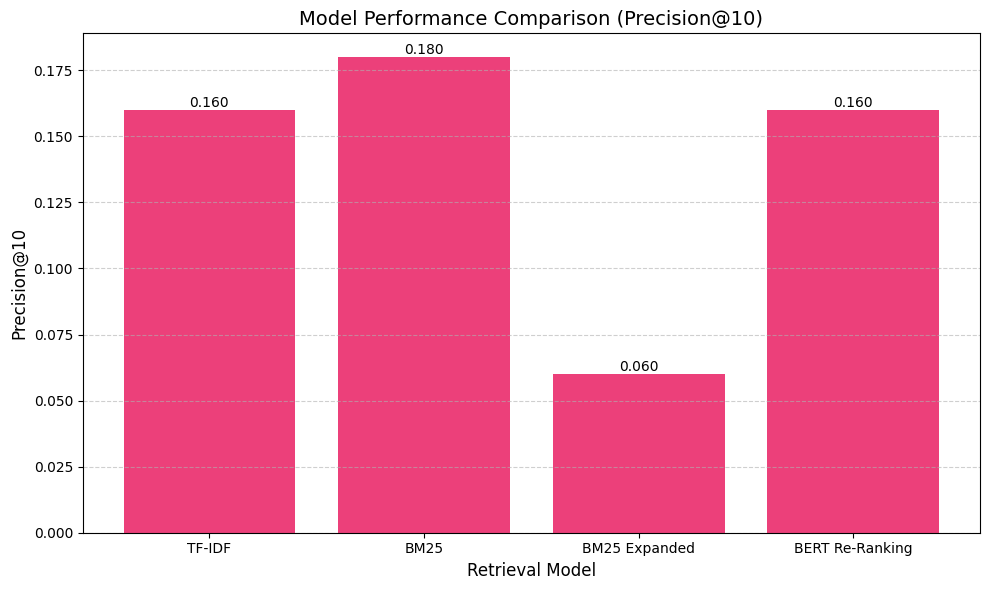

In [ ]:
import matplotlib.pyplot as plt

# Create a bar chart to visualize Precision@10 for each retrieval model
plt.figure(figsize=(10,6))

# Plot Precision@10 values across different models
bars = plt.bar(
    df_metrics["Model"],
    df_metrics["Precision@10"],
    color="#EC407A"
)

# Set chart title and axis labels
plt.title("Model Performance Comparison (Precision@10)", fontsize=14)
plt.xlabel("Retrieval Model", fontsize=12)
plt.ylabel("Precision@10", fontsize=12)

# Annotate each bar with its exact Precision@10 value
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha='center',
        va='bottom',
        fontsize=10
    )

# Add horizontal grid lines to improve readability
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Adjust layout to avoid overlapping elements
plt.tight_layout()

# Display the plot
plt.show()

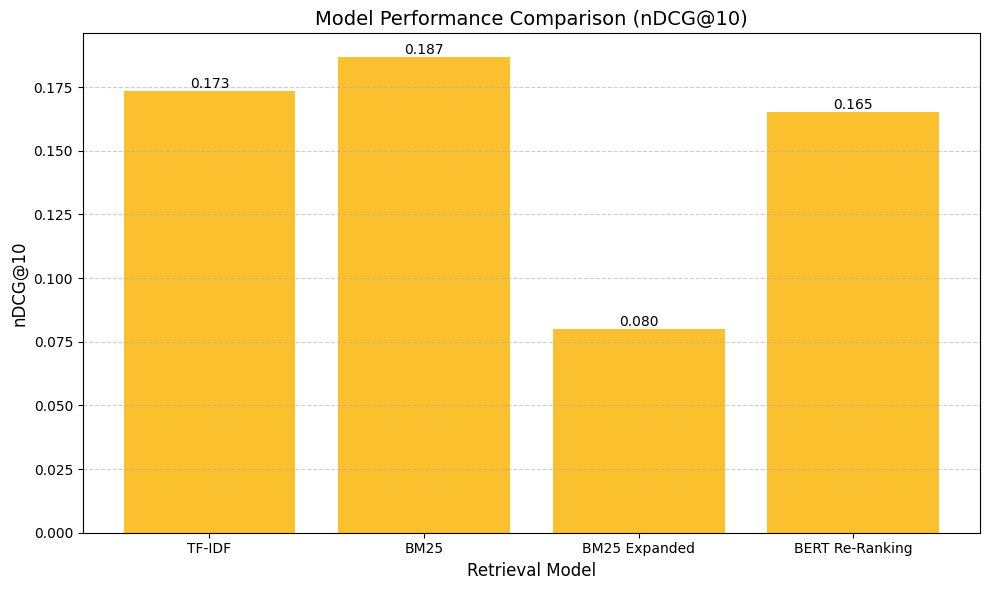

In [ ]:
import matplotlib.pyplot as plt

# Create a bar chart to visualize nDCG@10 for each retrieval model
plt.figure(figsize=(10,6))

# Plot nDCG@10 values for all retrieval models
bars = plt.bar(
    df_metrics["Model"],
    df_metrics["nDCG@10"],
    color="#FBC02D"
)

# Set chart title and axis labels
plt.title("Model Performance Comparison (nDCG@10)", fontsize=14)
plt.xlabel("Retrieval Model", fontsize=12)
plt.ylabel("nDCG@10", fontsize=12)

# Annotate each bar with its exact nDCG@10 value
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha='center',
        va='bottom',
        fontsize=10
    )

# Add horizontal grid lines to improve readability
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Adjust layout to ensure clean visualization
plt.tight_layout()

# Display the plot
plt.show()

## Discussion & Conclusion

## Discussion

This project demonstrated the development of a complete Arabic Information Retrieval (IR) system that integrates traditional and neural retrieval models.  
Through a series of experiments, we observed clear differences in performance across the classical statistical models (TF-IDF and BM25), query expansion techniques, and neural re-ranking using AraBERT.

### 1. Classical Retrieval Models (TF-IDF & BM25)
TF-IDF performed reasonably well for simple lexical matching; however, BM25 consistently outperformed it across most queries.  
This is expected, as BM25 accounts for both term frequency and document length normalization, making it more robust for ranking short and informal text such as tweets.

### 2. Query Expansion (Exploratory Analysis)
Query expansion using Word2Vec embeddings was explored as an additional enhancement to the retrieval process.  
While this technique showed potential in expanding short queries, its impact on overall performance was limited due to the short and informal nature of tweet-based documents.  
Therefore, query expansion was treated as an exploratory component rather than a core retrieval stage in the final evaluation.


### 3. Neural Re-ranking with AraBERT
AraBERT achieved the best overall performance in terms of MAP, nDCG, and Precision@10.  
Unlike keyword-based models, AraBERT captures semantic meaning and contextual relationships within the text.  
This allowed the model to retrieve documents that were relevant even when the exact query terms did not appear in the tweet.

### 4. Interpretation of Results
- Classical models excel at **lexical matching**, but struggle with semantic similarity.  
- Query expansion helps when the original query is short or lacks context.  
- Neural models such as **AraBERT** provide the strongest rankings because they understand context and can capture deeper meaning.  

Overall, the results highlight the importance of combining multiple retrieval stages—BM25 for initial retrieval and BERT for refined semantic ranking.

## Conclusion

This project successfully implemented a full Arabic IR pipeline, starting from preprocessing and indexing, through traditional ranking models, and finally incorporating neural re-ranking.  
The experiments demonstrated that combining classical and neural approaches leads to significantly improved retrieval quality.

### Key findings:
1. **BM25** is the most reliable model for initial retrieval.
2. **Query Expansion** can enhance performance for short or ambiguous queries.
3. **AraBERT Re-ranking** achieves the highest accuracy by leveraging semantic understanding.

### Future Work
- Experimenting with more advanced Arabic language models (e.g., AraBERTv3, CAMeLBERT, GPT-based retrieval).
- Using larger and more diverse datasets to improve generalization.
- Incorporating metadata such as hashtags, user information, or conversation threads.
- Building a full search engine interface for real-time Arabic information retrieval.

In conclusion, the integration of BM25 with neural models such as AraBERT provides a powerful hybrid retrieval system capable of handling the linguistic complexity of Arabic text.